In [10]:
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import json
%matplotlib inline

### выгрузка json

In [11]:
f = json.load(open("fns_fiscal.json", encoding='utf-8'))

In [12]:
f[0]['payload']

'{"protocolVersion":2,"operationType":1,"cashTotalSum":0,"shiftNumber":24,"counterSubmissionSum":0,"items":[{"measure":"кВт.ч","name":"Электроснабжение","quantity":225,"ndsRate":1,"price":223,"ndsSum":8363,"calculationTypeSign":4,"calculationSubjectSign":4,"sum":50175}],"totalSum":50175,"ecashTotalSum":50175,"nds18":8363,"dateTime":"2020-09-16","receiptCode":3,"taxationType":1,"requestNumber":556,"internetSign":1,"senderAddress":"onlineoplata@esplus.ru","postpaymentSum":0,"fiscalDocumentNumber":23206,"prepaymentSum":0,"buyerAddress":"onlineoplata@esplus.ru"}'

Переделаем в json формат

In [13]:
for el in f:
    el['payload'] = json.loads(el['payload'].strip("'"))
    
f[0]['payload']['items']

for el in f:
    el['payload']['items'] = el['payload']['items'][0]
    
f[0]['payload']['items']

{'measure': 'кВт.ч',
 'name': 'Электроснабжение',
 'quantity': 225,
 'ndsRate': 1,
 'price': 223,
 'ndsSum': 8363,
 'calculationTypeSign': 4,
 'calculationSubjectSign': 4,
 'sum': 50175}

In [14]:
for el in f:
    for name in el['payload'].keys():
        el[name] = el['payload'][name]
    del el['payload']
    for item_name in el['items']:
        el[f"items.{item_name}"] = el['items'][item_name]
    del el['items']

In [15]:
f[0]

{'id': 778607116,
 'id1': 'f883d93f29585bd840035b6ca7541ee4',
 'id2': 'ed4adb3df8dddc71d83e6f33c5d68732',
 'protocolVersion': 2,
 'operationType': 1,
 'cashTotalSum': 0,
 'shiftNumber': 24,
 'counterSubmissionSum': 0,
 'totalSum': 50175,
 'ecashTotalSum': 50175,
 'nds18': 8363,
 'dateTime': '2020-09-16',
 'receiptCode': 3,
 'taxationType': 1,
 'requestNumber': 556,
 'internetSign': 1,
 'senderAddress': 'onlineoplata@esplus.ru',
 'postpaymentSum': 0,
 'fiscalDocumentNumber': 23206,
 'prepaymentSum': 0,
 'buyerAddress': 'onlineoplata@esplus.ru',
 'items.measure': 'кВт.ч',
 'items.name': 'Электроснабжение',
 'items.quantity': 225,
 'items.ndsRate': 1,
 'items.price': 223,
 'items.ndsSum': 8363,
 'items.calculationTypeSign': 4,
 'items.calculationSubjectSign': 4,
 'items.sum': 50175}

In [16]:
df = pd.DataFrame(f)

### Выведем столбцы, у которых больше 50% пропущенных значение

In [17]:
del_cols = df.columns[df.isna().sum()>400]

In [18]:
print(del_cols)

Index(['protocolVersion', 'counterSubmissionSum', 'nds18', 'internetSign',
       'senderAddress', 'postpaymentSum', 'prepaymentSum', 'buyerAddress',
       'items.measure', 'items.ndsRate', 'items.ndsSum',
       'items.calculationTypeSign', 'items.calculationSubjectSign',
       'ndsCalculated20', 'ndsNo', 'userProperty', 'ndsCalculated18',
       'items.ndsCalculated18', 'provisionSum', 'sellerAddress',
       'fiscalDocumentFormatVer', 'propertiesUser', 'propertiesData',
       'prepaidSum', 'paymentAgentType', 'fnsSite', 'creditSum',
       'items.paymentType', 'items.nds', 'authorityUri', 'items.productType',
       'fnsUrl', 'nds10', 'items.nomenclatureCode', 'nds0', 'items.nds0',
       'addressToCheckFiscalSign', 'nds20', 'retailAddress', 'items.ndsNo',
       'items.nds10', 'ndsCalculated10', 'code', 'operatorPhoneToTransfer',
       'operatorToReceivePhone', 'operatorTransferAddress',
       'operatorTransferInn', 'operatorTransferName', 'paymentAgentOperation',
       'paym

In [19]:
df['protocolVersion'].isna().sum()

645

In [20]:
df = df.drop(del_cols, axis=1)
df.index = df['id']
del df['id']
print(df)

                                        id1                               id2  \
id                                                                              
778607116  f883d93f29585bd840035b6ca7541ee4  ed4adb3df8dddc71d83e6f33c5d68732   
778607235  f883d93f29585bd840035b6ca7541ee4  9f7252e49be5f81eb0ff7975c4f8a884   
778606945  a5c8a6e35ef171db60f8bbd2c426605d  0d8ba676db6993a06fa5436c4a4b8490   
778607027  a5c8a6e35ef171db60f8bbd2c426605d  703647252fb07fcbfb46bbd46cff8514   
778607205  a5c8a6e35ef171db60f8bbd2c426605d  4451fcccc8234a260f4998670cd03b56   
...                                     ...                               ...   
666907782  aae0bfe30cb4c8a224f14abb74b92db8  50b88cad3cce59f5ee543386e39b092f   
666907959  aae0bfe30cb4c8a224f14abb74b92db8  d9239c7746f939af5fc7e2869353b73f   
666908152  aae0bfe30cb4c8a224f14abb74b92db8  4a93d5bd0ea170778618f3bcd8cc62cd   
666909002  21b39d0515aa702de267b1197ba59283  36c9f96565c28eba2c40bd640f2de5da   
666909138  21b39d0515aa702de


удалим id1, id, dateTime

In [21]:
df = df.drop(['id1', 'id2', 'dateTime'], axis=1)

In [22]:
df.head()

,operationType,cashTotalSum,shiftNumber,totalSum,ecashTotalSum,receiptCode,taxationType,requestNumber,fiscalDocumentNumber,items.name,items.quantity,items.price,items.sum
id,,,,,,,,,,,,,
778607116,1,0,24,50175,50175,3.0,1,556,23206,Электроснабжение,225.0,223,50175
778607235,1,0,24,25420,25420,3.0,1,565,23215,Электроснабжение,62.0,410,25420
778606945,1,0,14,6000,6000,3.0,0,529,75001,Аванс за услуги связи 9091082396,1.0,6000,6000
778607027,1,0,14,10000,10000,3.0,0,537,75009,Аванс за услуги связи 9092626865,1.0,10000,10000
778607205,1,0,14,20000,20000,3.0,0,553,75025,Аванс за услуги связи 9089895687,1.0,20000,20000


избавимся от ненужных параметров

In [25]:
df['operationType'].value_counts()
df['cashTotalSum'].value_counts()
df['receiptCode'].value_counts()
df['fiscalDocumentNumber'].value_counts()

107334    2
141032    2
89394     1
17691     1
9500      1
         ..
238215    1
227977    1
240266    1
107147    1
49941     1
Name: fiscalDocumentNumber, Length: 798, dtype: int64

In [26]:
df = df.drop(['receiptCode', 'cashTotalSum','operationType', 'fiscalDocumentNumber', 'requestNumber', 'shiftNumber', 'ecashTotalSum'], axis=1)

In [27]:
df.columns

Index(['totalSum', 'taxationType', 'items.name', 'items.quantity',
       'items.price', 'items.sum'],
      dtype='object')

In [28]:
df.head()

,totalSum,taxationType,items.name,items.quantity,items.price,items.sum
id,,,,,,
778607116,50175,1,Электроснабжение,225.0,223,50175
778607235,25420,1,Электроснабжение,62.0,410,25420
778606945,6000,0,Аванс за услуги связи 9091082396,1.0,6000,6000
778607027,10000,0,Аванс за услуги связи 9092626865,1.0,10000,10000
778607205,20000,0,Аванс за услуги связи 9089895687,1.0,20000,20000


Рассмотрим items.name

In [29]:
df['items.name'].value_counts()

Услуги связи                                          49
Лицензия на использование ПО сайта checkyour.name     28
Электроснабжение                                      19
Перевозка пассажиров и багажа                         18
Поездка за наличные                                   18
                                                      ..
Вода Каролина Минерале 1,5л негаз                      1
Хлеб из пшен. муки  форм. 0,5-0,55кг                   1
Аванс за услуги связи 9649545447                       1
маска медиц. 3-х слойная №1  (05.2020 до 01.05.25)     1
ТРК №2 Бензин автомобильный ЭКТО-92 (АИ-92-К5)         1
Name: items.name, Length: 560, dtype: int64

Заменим  ё на е

In [30]:
df['items.name'].str.contains('ё', regex=False).any()
df['items.name'] = df['items.name'].str.replace('ё', 'е').replace('Ё', 'Е')
df['items.name'].value_counts()

Услуги связи                                          49
Лицензия на использование ПО сайта checkyour.name     28
Оплата проезда за наличный расчет                     20
Электроснабжение                                      19
Поездка за наличные                                   18
                                                      ..
Вода Каролина Минерале 1,5л негаз                      1
Хлеб из пшен. муки  форм. 0,5-0,55кг                   1
Аванс за услуги связи 9649545447                       1
маска медиц. 3-х слойная №1  (05.2020 до 01.05.25)     1
ТРК №2 Бензин автомобильный ЭКТО-92 (АИ-92-К5)         1
Name: items.name, Length: 559, dtype: int64

Убираем номера телефонов, даты, номера договоров

In [33]:
regex_tel_number = r' \+?[7,8]?\s*\d{3}\s*\d{3}\s*\d{2}\s*\d{2}\b'
df['items.name'].str.contains(regex_tel_number, regex=True).sum()
df['items.name'] = df['items.name'].str.replace(regex_tel_number, '', regex=True)
df['items.name'].value_counts()

regex_date = r'\d{2}.\d{2}.\d{4} \d{2}:\d{2}'
df['items.name'].str.contains(regex_date, regex=True).sum()
df['items.name'] = df['items.name'].str.replace(regex_date, '', regex=True)
df['items.name'].value_counts()

regex_dog_num = r' №\d*\b'
df['items.name'].str.contains(regex_dog_num, regex=True).sum()
df['items.name'] = df['items.name'].str.replace(regex_dog_num, '', regex=True)
df['items.name'].value_counts()

Аванс за услуги связи                                126
Услуги связи                                          49
Лицензия на использование ПО сайта checkyour.name     28
Оплата услуг связи                                    26
Оплата проезда за наличный расчет                     20
                                                    ... 
Сигареты L&M Blue Label                                1
Напитки Манутин Дью 0,5л                               1
Поездка-82841455-275-0193                              1
3021692 Банан ВЫГОДНО фас.1кг                          1
Сигареты "Винстон" Суперслимс синий                    1
Name: items.name, Length: 378, dtype: int64

Число уникальных значений переменной items.name уменьшилось с 560 до 378

### Построение модели

In [41]:
df['items.name'] = df['items.name'].str.replace('\.', '', regex=True).replace('"', '', regex=True).replace('\(', '', regex=True).replace('\'', '', regex=True) \
                                    .replace('\%', '', regex=True).replace('\*', '', regex=True).replace('=', '', regex=True).replace('\[', '', regex=True) \
                                    .replace('\]', '', regex=True).replace('№', '', regex=True).replace('/', ' ', regex=True).replace('#', '', regex=True) \
                                    .replace(':', '', regex=True).replace('-', '', regex=True).replace(';', '', regex=True).replace(',', '', regex=True) \
                                    .replace('<', '', regex=True).replace('>', '', regex=True).replace('!', '', regex=True).replace(r'\d', '', regex=True) \
                                    .replace('\)', '', regex=True)
df['items.name'] = df['items.name'].str.lower()
df['items.name'].value_counts()

df['items.name'] = df['items.name'].str.replace(r'\bдля\b', ' ', regex=True).replace(r'\bи\b', ' ', regex=True).replace(r'\bс\b', ' ', regex=True) \
                                    .replace(r'\bв\b', ' ', regex=True).replace(r'\bза\b', ' ', regex=True).replace(r'\bна\b', ' ', regex=True) \
                                    .replace(r'\bшт\b', '', regex=True).replace(r'\bгр\b', '', regex=True).replace(r'\bл\b', '', regex=True) \
                                    .replace(r'\bкг\b', '', regex=True).replace(r'\bг\b', '', regex=True).replace(r'\bиз\b', '', regex=True) \
                                    .replace(r'\bшт\b', '', regex=True).replace(r'\bквм\b', '', regex=True).replace(r'\bруб\b', '', regex=True)
df['items.name'] = df['items.name'].replace('  ', ' ', regex=True)

df['items.name'].value_counts()
df[df['items.name'].str.contains(r'\b\w{1}\b', regex=True)]['items.name']
df[df['items.name'].str.contains('\\', regex=False)]['items.name']
df['items.name'] = df['items.name'].replace(r'\\', ' ', regex=True)
df[df['items.name'].str.contains('\\', regex=False)]['items.name']
df['items.name'] = df['items.name'].replace(r'\b\w{1}\b', '', regex=True)
names = set(list(df['items.name']))
def build_corpus():
    "Creates a list of lists containing words from each sentence"
    corpus = []
    for name in names:
        word_list = name.split()
        corpus.append(word_list)
            
    return corpus

corpus = build_corpus()

In [42]:
corpus

[['регистрация', 'домена', 'comwaru', 'год'],
 ['филип', 'морис', 'kомпакт', 'ред', 'яркий'],
 ['пополнение', 'лицевого', 'счета'],
 ['бензин', 'аик'],
 ['ps', 'тяга', 'рулевая'],
 ['трк', 'бензин', 'автомобильный', 'экто', 'аик'],
 ['кокакола', 'ср'],
 ['одноразстакан', 'мл', 'бкмажн'],
 ['аик', 'бензин', 'gdrive'],
 ['прием', 'ставки'],
 ['сигареты', '&', 'blue', 'label'],
 ['леденцы', 'холлс', 'мед', 'лимон', 'дирол'],
 ['термометр', 'bwell', 'wf', 'электронный'],
 ['elle', 'decoration', 'элль', 'декорейшн', 'русское', 'издание'],
 ['сигареты', 'максим', 'классичмм', 'red'],
 ['разовый', 'безденежный'],
 ['пакет', 'питькофе'],
 ['сигареты', 'philip', 'morris', 'dark', 'blue', 'пач'],
 ['напбез', 'алк', 'негазхолодный', 'чай', 'липтон', 'лимон'],
 ['некст', 'вайолет', 'спешл', 'мрц'],
 ['поездка'],
 ['сигареты', 'лд', 'ав', 'импульс', 'компакт', 'джти'],
 ['приход'],
 ['лапша', 'куриная'],
 ['хлеб', 'формовой'],
 ['виагра', 'табп', 'мг'],
 ['напиток', 'энергетdrive', 'me'],
 ['давыдо

In [ ]:
from gensim.models import Word2Vec
from gensim.models import word2vec, KeyedVectors
from sklearn.manifold import TSNE

model = word2vec.Word2Vec(corpus, vector_size=100, window=20, min_count=1, workers=4)
model_lowered = word2vec.Word2Vec(corpus, vector_size=100, window=20, min_count=5, workers=4)

def tsne_plot(model):
    "Creates and TSNE model and plots it"
    labels = []
    tokens = []

    for word in model.wv.key_to_index:
        tokens.append(model.wv[word])
        labels.append(word)
    
    tsne_model = TSNE(perplexity=40, n_components=2, init='pca', n_iter=2500, random_state=23)
    new_values = tsne_model.fit_transform(tokens)

    x = []
    y = []
    for value in new_values:
        x.append(value[0])
        y.append(value[1])
        
    plt.figure(figsize=(16, 16)) 
    for i in range(len(x)):
        plt.scatter(x[i],y[i])
        plt.annotate(labels[i],
                     xy=(x[i], y[i]),
                     xytext=(5, 2),
                     textcoords='offset points',
                     ha='right',
                     va='bottom')
    plt.show()

In [ ]:
tsne_plot(model)
tsne_plot(model_lowered)
word_vectors = model.wv
word_vectors.save('vectors.kv')
model2 = KeyedVectors.load('vectors.kv')

In [ ]:
model2.vectors

array([[-6.7603507e-04,  4.3124161e-04,  5.2540619e-03, ...,
        -7.4247769e-03,  9.7622856e-04,  6.4483723e-03],
       [-8.7024160e-03,  3.7911846e-03,  5.2784691e-03, ...,
        -2.6148825e-03, -9.4279563e-03,  4.5583760e-03],
       [ 8.9426110e-05,  3.1254967e-03, -6.8046548e-03, ...,
         4.6884367e-04,  8.2180472e-03, -7.0589366e-03],
       ...,
       [ 3.5314236e-03,  5.8631590e-03,  7.2940085e-03, ...,
         4.5736232e-03,  7.2130286e-03,  4.8426650e-03],
       [-6.1901836e-03,  3.2885093e-03, -3.3386559e-03, ...,
        -4.5713885e-03, -4.4877492e-03, -5.7173721e-03],
       [ 9.1855498e-03, -7.7404114e-03,  3.7006370e-03, ...,
         8.6630061e-03,  5.7803444e-03,  5.9827268e-03]], dtype=float32)

In [ ]:
w2v_vectors = model2.vectors # here you load vectors for each word in your model
w2v_indices = {word: model2.key_to_index[word] for word in model2.key_to_index} # here you load indices - with whom you can find an index of the particular word in your model
print(model2.index_to_key)

['сигареты', 'blue', 'аик', 'трк', 'мл', 'напиток', 'блю', 'компакт', 'бензин', 'по', 'вода', 'лд', 'аи', 'кофе', 'разовый', 'газ', 'пакет', 'винстон', 'winston', 'батон', 'пиво', 'перевозка', 'хлеб', 'джти', 'пэт', 'нарезной', 'американо', 'капучино', 'пирожок', 'экто', 'напитки', 'услуга', 'колонка', 'пач', 'автограф', 'энергетический', 'оплата', 'резинка', 'поездка', 'бат', 'зеленый', 'ред', 'билет', 'дтлк', 'compact', 'лимон', 'jti', 'kent', 'мята', 'паркер', 'чай', 'майка', 'услуги', 'связи', 'маршрут', 'полный', 'label', 'стики', 'балтика', 'вишня', 'rothmans', 'льготный', 'деми', 'клуб', 'автомобильный', 'ав', 'ст', 'игристое', 'вино', 'липтон', 'click', 'некст', 'xstyle', 'карте', 'неэтилированный', '&', 'жареный', 'питьевая', 'dirol', 'gdrive', 'перевозке', 'zb', 'moscato', 'полусладкое', 'мрц', 'morris', 'philip', 'ява', 'золотая', 'зажигалка', 'формовой', 'яблоки', 'heets', 'бут', 'источник', 'святой', 'упак', 'нап', 'ср', 'цм', 'яблоком', 'евро', 'спрей', 'ассортименте', 'п

In [ ]:
def vectorize(line): 
    words = []
    for word in line:
        w2v_idx = w2v_indices[word]
        words.append(w2v_vectors[w2v_idx])
        if words: 
            words = np.asarray(words)
            min_vec = words.min(axis=0)
            max_vec = words.max(axis=0)
            return np.concatenate((min_vec, max_vec))
        if not words:
            return None

In [ ]:
X = [vectorize(i) for i in corpus]
X

[array([-1.37873320e-03, -5.73755288e-03,  3.62236053e-03,  5.45179937e-04,
         8.78837053e-03, -4.80806688e-03, -1.93205336e-03, -3.07382853e-03,
        -2.73842551e-03,  3.65303131e-04,  4.84579941e-03,  3.69125046e-04,
         3.99057707e-03, -9.27871559e-03, -9.80234519e-03,  3.94562958e-04,
         8.26124940e-03, -3.66898137e-03,  7.27931643e-03, -5.60099632e-03,
         1.08570486e-04, -9.24280193e-03,  6.50659064e-03,  1.73593184e-03,
        -8.44981428e-03, -2.52407021e-03,  3.99395544e-03,  9.83244157e-04,
        -3.40247108e-03, -5.42668952e-03, -3.22189904e-03, -6.47570146e-03,
        -3.05360835e-03, -9.28927213e-03,  4.45404649e-03, -4.50481661e-03,
        -5.49287954e-03, -5.70415333e-03, -6.82834070e-04,  5.02129900e-04,
        -7.54170865e-03, -8.62593390e-03, -5.64553123e-03,  8.64801090e-03,
        -1.88272959e-03,  8.62208940e-03, -9.34031606e-03,  4.35036561e-03,
         8.58332776e-03,  7.96727464e-03, -7.91637693e-03,  6.53353380e-03,
         2.9

In [ ]:
len(X)

319

In [ ]:
del X[99]

In [ ]:
df_x = pd.DataFrame(X)

In [ ]:
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(metric='cosine', eps=0.07, min_samples=3)
cluster_labels = dbscan.fit_predict(df_x) # where X - is your matrix, where each row corresponds to one document (line) from the docs, you need to cluster
print(dbscan.labels_)

noise_amount = 0
for label in dbscan.labels_:
    if int(label) == -1:
        noise_amount += 1
print(noise_amount, 'из', len(dbscan.labels_))

[-1 -1 -1  0  1 -1  2  3  1 -1 -1  4  1 -1 -1 -1 -1  1 -1 -1 -1 -1  4  5
 -1 -1  5  5  4 -1  1  6  1 -1 -1 -1 -1 -1 -1 -1 -1  1 -1  7 -1  8 -1 -1
 -1 -1 -1 -1  9  3  1 -1 -1  1  1 10 -1 -1 10  1 11 -1 12 13 -1 -1  4 -1
 14  1 -1  3 -1  4 -1 -1 10 15  4  7 -1  1 15 -1 -1  5 -1 -1 16 13 -1 -1
 17 -1  3 18 -1 15 -1 -1 -1 -1 18  1 11 -1 -1 -1  1 -1  8 -1  6 -1 -1 -1
 -1  8 14  1 -1  4 -1 -1 -1 17 -1 -1  1 -1 17 -1  1 -1 -1  1 -1  9 17  1
 -1 -1 16 -1 -1 13 -1  8 -1 -1 -1  1  1 -1 14 -1 -1  4  0  0  6 -1 -1 11
 -1 -1 -1 10 -1 12 -1 -1 -1 -1 -1 -1 -1  7 -1 -1 -1 14 -1 -1 -1 -1 -1  1
 -1 -1 -1 -1 -1  8 -1 -1 19 16 -1  1 19 -1 -1 -1 -1 -1 -1 12  3 20 -1 -1
 -1 11 -1  4  3  1  1  3  1 -1  7  1 -1  4  0 -1 -1 -1  1  2 -1 12 -1  2
 -1 -1  1 -1 12 19 -1 -1 -1 -1  1 19  1 -1  7 -1 -1 -1 13 11 -1 -1 -1 -1
  3 -1 -1  5 -1 -1 20 -1 -1 -1 -1 18  1  1  1 -1 -1 -1 14 -1 -1  2 11 -1
  5 15  1 20 -1 19  1 -1 -1 -1 -1 18  5  9 -1 -1 12 20 -1 12 18 -1 11 -1
 -1 -1  1 -1 19 -1]
178 из 318


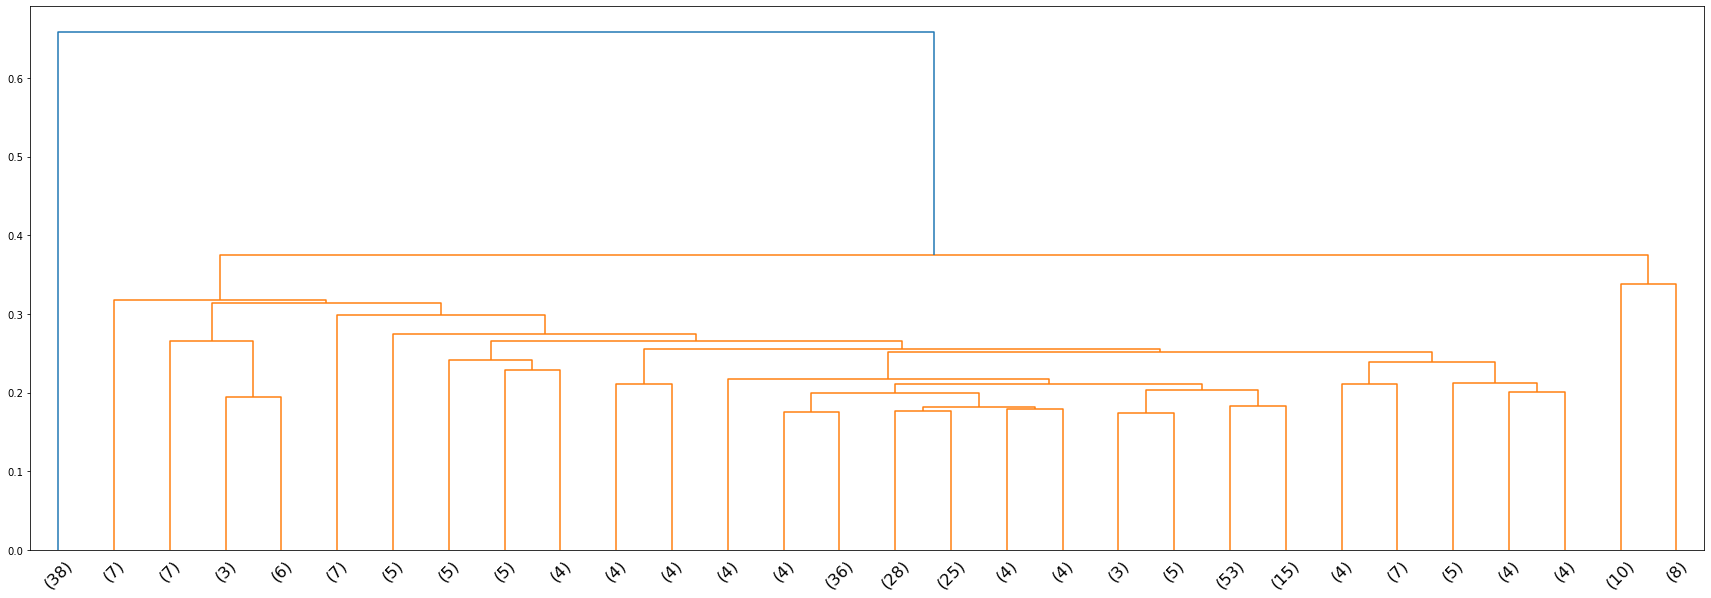

In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage

linked = linkage(X, 'ward')
# 500 100
plt.figure(figsize=(30, 10))
dendrogram(linked,
            p=30,
            truncate_mode='lastp',
            orientation='top',
            distance_sort='ascending',
            leaf_font_size=16,
        )
plt.show()

In [ ]:
from sklearn.cluster import AgglomerativeClustering

cluster = AgglomerativeClustering(n_clusters=42, affinity='euclidean', linkage='ward')
cluster.fit_predict(df_x)
cluster.labels_

array([14,  3,  0, 15, 31,  1, 17, 24, 31, 12, 38, 39, 31,  8,  2,  8,  2,
       31,  4, 38,  3,  2, 39, 32,  1, 14, 32, 32, 39, 14, 31, 34, 31, 13,
       14,  3,  7, 12,  1,  1,  1, 31, 38, 25,  1, 29,  1,  1,  4,  3,  3,
        6, 23, 24, 31,  3,  7, 31, 31, 37,  3,  3, 37, 31, 27, 12, 36, 28,
        3,  7, 39,  1, 19, 31,  7, 24,  5, 39, 14, 13, 37, 21, 39, 25, 38,
       31, 21, 40,  8, 32, 11,  3, 30, 28,  3,  2, 41,  6, 24, 33,  9, 21,
        1,  1,  1,  1, 33, 31, 27, 18,  1,  1, 31, 14, 29,  6, 34, 38,  1,
       18, 35, 29, 19, 31,  7, 39, 14,  3,  7, 41,  8,  8, 31,  4, 41,  4,
       31, 13,  7, 31,  1, 23, 41, 31,  1,  0, 30, 16,  6, 28, 38, 29, 18,
       38,  7, 31, 31,  3, 19, 13,  7, 39, 15, 15, 34,  7,  8, 27,  8,  5,
        2, 37,  3, 36, 18, 14, 13, 18,  2, 20, 13, 25, 18, 12,  4, 19,  0,
        3,  3,  1,  0, 31, 38, 16,  2,  9, 14, 29,  4, 18, 10, 30,  8, 31,
       10, 13, 26, 13, 38,  1,  8, 36, 24, 22, 38,  8,  3, 27,  8, 39, 24,
       31, 31, 24, 31,  1